## 1. Data collection
The data comes from the Kaggle competition "Home Credit Default Risk".
We downloaded the zip file from Kaggle and stored it in Google Drive.
First we mount Google Drive so Colab can read the file.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


Check that the zip file is in the Drive folder.

In [2]:
!ls -lh /content/drive/MyDrive/home_credit

total 689M
drwx------ 2 root root 4.0K Oct 17 15:49 data
-rw------- 1 root root 689M Oct 17 14:24 home-credit-default-risk.zip


Unzip the dataset. This is run only once. The extracted CSV files are saved in
a "data" folder inside Drive.

In [3]:
!unzip -q /content/drive/MyDrive/home_credit/home-credit-default-risk.zip -d /content/drive/MyDrive/home_credit/data

replace /content/drive/MyDrive/home_credit/data/HomeCredit_columns_description.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

Check the extracted files. The dataset has 8 data files and one file that
describes the columns (HomeCredit_columns_description.csv).

In [4]:
!ls -lh /content/drive/MyDrive/home_credit/data

total 2.5G
-rw------- 1 root root  26M Dec 11  2019 application_test.csv
-rw------- 1 root root 159M Dec 11  2019 application_train.csv
-rw------- 1 root root 359M Dec 11  2019 bureau_balance.csv
-rw------- 1 root root 163M Dec 11  2019 bureau.csv
-rw------- 1 root root 405M Dec 11  2019 credit_card_balance.csv
-rw------- 1 root root  37K Dec 11  2019 HomeCredit_columns_description.csv
-rw------- 1 root root 690M Dec 11  2019 installments_payments.csv
-rw------- 1 root root 375M Dec 11  2019 POS_CASH_balance.csv
-rw------- 1 root root 387M Dec 11  2019 previous_application.csv
-rw------- 1 root root 524K Dec 11  2019 sample_submission.csv


Store the data path.

In [8]:
path = "/content/drive/MyDrive/home_credit/data/"

Load the main table, application_train. Each row is one loan application and TARGET shows whether the client had repayment difficulty.

Import the libraries.

In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [9]:
work = pd.read_csv(path + "application_train.csv")

Display the data.

In [10]:
display(work)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [11]:
work.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


Check the column types and non-null counts.

In [12]:
work.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


Check the number of rows and columns.

In [13]:
work.shape

(307511, 122)

**Observation**:

Load the other tables. They contain each client's credit history.

In [14]:
test = pd.read_csv(path + "application_test.csv")
bureau = pd.read_csv(path + "bureau.csv")
bureau_bal = pd.read_csv(path + "bureau_balance.csv")
prev = pd.read_csv(path + "previous_application.csv")
pos = pd.read_csv(path + "POS_CASH_balance.csv")
inst = pd.read_csv(path + "installments_payments.csv")
cc = pd.read_csv(path + "credit_card_balance.csv")
col_desc = pd.read_csv(path + "HomeCredit_columns_description.csv", encoding="latin-1")

Check the size of every table.

In [15]:
print("application_train:", work.shape)
print("application_test:", test.shape)
print("bureau:", bureau.shape)
print("bureau_balance:", bureau_bal.shape)
print("previous_application:", prev.shape)
print("POS_CASH_balance:", pos.shape)
print("installments_payments:", inst.shape)
print("credit_card_balance:", cc.shape)

application_train: (307511, 122)
application_test: (48744, 121)
bureau: (1716428, 17)
bureau_balance: (27299925, 3)
previous_application: (1670214, 37)
POS_CASH_balance: (10001358, 8)
installments_payments: (13605401, 8)
credit_card_balance: (3840312, 23)


**Observation:** history tables have many more rows than the main table because each client can have many past credits, applications or payments.

Dataset description: what each table contains and how they are linked (SK_ID_CURR = client, SK_ID_BUREAU = bureau credit, SK_ID_PREV = previous application).

In [16]:
description = pd.DataFrame({
    "table": ["application_train", "application_test", "bureau", "bureau_balance",
              "previous_application", "POS_CASH_balance", "installments_payments", "credit_card_balance"],
    "key": ["SK_ID_CURR", "SK_ID_CURR", "SK_ID_CURR / SK_ID_BUREAU", "SK_ID_BUREAU",
            "SK_ID_CURR / SK_ID_PREV", "SK_ID_PREV", "SK_ID_PREV", "SK_ID_PREV"],
    "content": ["One row per application, includes TARGET",
                "Same as train, without TARGET",
                "Previous credits from other institutions",
                "Monthly status of bureau credits",
                "Previous applications at Home Credit",
                "Monthly snapshots of POS and cash loans",
                "Repayment history of previous credits",
                "Monthly credit card balance snapshots"],
    "rows": [work.shape[0], test.shape[0], bureau.shape[0], bureau_bal.shape[0],
             prev.shape[0], pos.shape[0], inst.shape[0], cc.shape[0]],
    "columns": [work.shape[1], test.shape[1], bureau.shape[1], bureau_bal.shape[1],
                prev.shape[1], pos.shape[1], inst.shape[1], cc.shape[1]]
})
display(description)

,table,key,content,rows,columns
0,application_train,SK_ID_CURR,"One row per application, includes TARGET",307511,122
1,application_test,SK_ID_CURR,"Same as train, without TARGET",48744,121
2,bureau,SK_ID_CURR / SK_ID_BUREAU,Previous credits from other institutions,1716428,17
3,bureau_balance,SK_ID_BUREAU,Monthly status of bureau credits,27299925,3
4,previous_application,SK_ID_CURR / SK_ID_PREV,Previous applications at Home Credit,1670214,37
5,POS_CASH_balance,SK_ID_PREV,Monthly snapshots of POS and cash loans,10001358,8
6,installments_payments,SK_ID_PREV,Repayment history of previous credits,13605401,8
7,credit_card_balance,SK_ID_PREV,Monthly credit card balance snapshots,3840312,23


In [17]:
description.to_csv("dataset_description.csv", index=False)

Target variable. TARGET = 0 means no repayment difficulty and TARGET = 1 means repayment difficulty. We count each class to see whether the data is balanced.

In [18]:
display(work["TARGET"].value_counts())
display(work["TARGET"].value_counts(normalize=True) * 100)

,count
TARGET,
0,282686
1,24825


,proportion
TARGET,
0,91.927118
1,8.072882


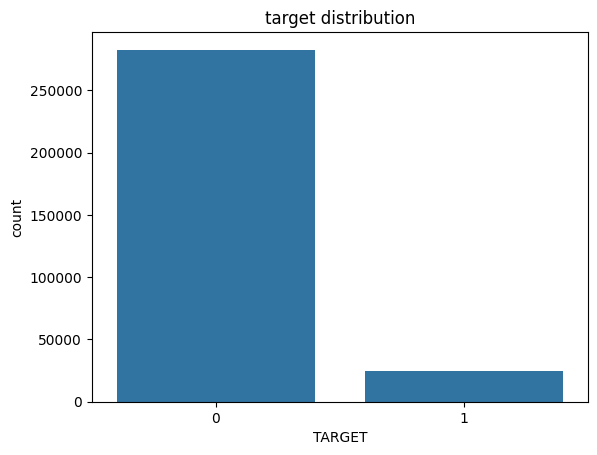

In [19]:
sns.countplot(x=work["TARGET"])
plt.title("target distribution")
plt.xlabel("TARGET")
plt.ylabel("count")
plt.show()

**Observation** [8]% of clients had repayment difficulty and [92]% did not, so the data is highly imbalanced. Accuracy would be misleading; later we should use ROC-AUC / PR-AUC and handle imbalance with class weights or resampling.

Missing values. We count missing values in each column and show only the columns that have some.

In [20]:
missing = work.isna().sum()
display(missing[missing > 0].sort_values(ascending=False))

,0
COMMONAREA_MEDI,214865
COMMONAREA_MODE,214865
COMMONAREA_AVG,214865
NONLIVINGAPARTMENTS_MODE,213514
NONLIVINGAPARTMENTS_MEDI,213514
...,...
EXT_SOURCE_2,660
AMT_GOODS_PRICE,278
AMT_ANNUITY,12
CNT_FAM_MEMBERS,2


Percentage of missing values per column.

In [21]:
missing_pct = (work.isna().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]
print(len(missing_pct), "columns have missing values")
print((missing_pct > 50).sum(), "columns have more than 50% missing")
display(missing_pct.head(20))

67 columns have missing values
41 columns have more than 50% missing


,0
COMMONAREA_AVG,69.872297
COMMONAREA_MODE,69.872297
COMMONAREA_MEDI,69.872297
NONLIVINGAPARTMENTS_MEDI,69.432963
NONLIVINGAPARTMENTS_MODE,69.432963
NONLIVINGAPARTMENTS_AVG,69.432963
FONDKAPREMONT_MODE,68.386172
LIVINGAPARTMENTS_AVG,68.354953
LIVINGAPARTMENTS_MEDI,68.354953
LIVINGAPARTMENTS_MODE,68.354953


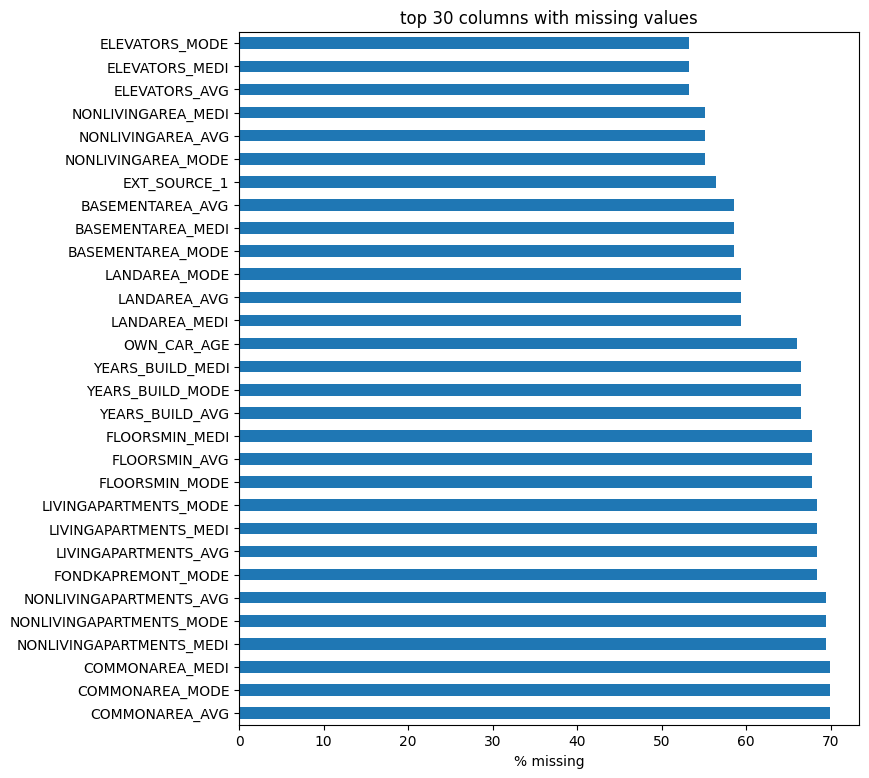

In [22]:
plt.figure(figsize=(8, 9))
missing_pct.head(30).plot.barh()
plt.title("top 30 columns with missing values")
plt.xlabel("% missing")
plt.show()

**Observation:**[x] columns have missing values and [x] have more than 50% missing. The worst are the housing features (*_AVG, *_MODE, *_MEDI) and OWN_CAR_AGE. Very sparse columns can be dropped and the rest imputed later.

Missing values in the other tables.

In [23]:
display(bureau.isna().sum()[bureau.isna().sum() > 0])
display(prev.isna().sum()[prev.isna().sum() > 0])

,0
DAYS_CREDIT_ENDDATE,105553
DAYS_ENDDATE_FACT,633653
AMT_CREDIT_MAX_OVERDUE,1124488
AMT_CREDIT_SUM,13
AMT_CREDIT_SUM_DEBT,257669
AMT_CREDIT_SUM_LIMIT,591780
AMT_ANNUITY,1226791


,0
AMT_ANNUITY,372235
AMT_CREDIT,1
AMT_DOWN_PAYMENT,895844
AMT_GOODS_PRICE,385515
RATE_DOWN_PAYMENT,895844
RATE_INTEREST_PRIMARY,1664263
RATE_INTEREST_PRIVILEGED,1664263
NAME_TYPE_SUITE,820405
CNT_PAYMENT,372230
PRODUCT_COMBINATION,346


Duplicate

In [24]:
work.duplicated().sum()

np.int64(0)

In [25]:
work["SK_ID_CURR"].duplicated().sum()

np.int64(0)

In [26]:
print(bureau.duplicated().sum(), prev.duplicated().sum(), inst.duplicated().sum())

0 0 0


**Observation:**There are [0] duplicate rows and [0] duplicate client IDs, so nothing needs to be removed.

Statistical summary of the numeric columns.

In [27]:
work.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


Summary of the text (categorical) columns.

In [28]:
work.describe(include="object")

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE,WEEKDAY_APPR_PROCESS_START,ORGANIZATION_TYPE,FONDKAPREMONT_MODE,HOUSETYPE_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE
count,307511,307511,307511,307511,306219,307511,307511,307511,307511,211120,307511,307511,97216,153214,151170,161756
unique,2,3,2,2,7,8,5,6,6,18,7,58,4,3,7,2
top,Cash loans,F,N,Y,Unaccompanied,Working,Secondary / secondary special,Married,House / apartment,Laborers,TUESDAY,Business Entity Type 3,reg oper account,block of flats,Panel,No
freq,278232,202448,202924,213312,248526,158774,218391,196432,272868,55186,53901,67992,73830,150503,66040,159428


Unusual values. DAYS_EMPLOYED has a suspiciously common value.

In [29]:
work["DAYS_EMPLOYED"].value_counts().head()

,count
DAYS_EMPLOYED,
365243,55374
-200,156
-224,152
-230,151
-199,151


In [30]:
(work["DAYS_EMPLOYED"] == 365243).sum()

np.int64(55374)

In [31]:
(work["DAYS_EMPLOYED"] == 365243).mean() * 100

np.float64(18.00716071945394)

In [32]:
work[work["DAYS_EMPLOYED"] == 365243]["NAME_INCOME_TYPE"].value_counts()

,count
NAME_INCOME_TYPE,
Pensioner,55352
Unemployed,22


In [33]:
work["CODE_GENDER"].value_counts()

,count
CODE_GENDER,
F,202448
M,105059
XNA,4


**Observation**:DAYS_EMPLOYED = 365243 appears in about [18]% of rows. That is about 1,000 years, so it is a placeholder (mostly [pensioners]). It should be replaced with NaN. CODE_GENDER has a few "XNA" (unknown) values.

Create new columns. DAYS_BIRTH and DAYS_EMPLOYED are negative days before the application, so we convert them to years. The placeholder 365243 is replaced with NaN.

In [34]:
work["DAYS_EMPLOYED"] = work["DAYS_EMPLOYED"].replace(365243, np.nan)
work["AGE_YEARS"] = -work["DAYS_BIRTH"] / 365
work["YEARS_EMPLOYED"] = -work["DAYS_EMPLOYED"] / 365
work["CREDIT_INCOME_RATIO"] = work["AMT_CREDIT"] / work["AMT_INCOME_TOTAL"]

new_table = work[["SK_ID_CURR", "DAYS_BIRTH", "AGE_YEARS", "DAYS_EMPLOYED", "YEARS_EMPLOYED"]]
display(new_table)

,SK_ID_CURR,DAYS_BIRTH,AGE_YEARS,DAYS_EMPLOYED,YEARS_EMPLOYED
0,100002,-9461,25.920548,-637.0,1.745205
1,100003,-16765,45.931507,-1188.0,3.254795
2,100004,-19046,52.180822,-225.0,0.616438
3,100006,-19005,52.068493,-3039.0,8.326027
4,100007,-19932,54.608219,-3038.0,8.323288
...,...,...,...,...,...
307506,456251,-9327,25.553425,-236.0,0.646575
307507,456252,-20775,56.917808,NaN,NaN
307508,456253,-14966,41.002740,-7921.0,21.701370
307509,456254,-11961,32.769863,-4786.0,13.112329


Outliers
Outliers in income. A boxplot shows extreme values (log scale because a few values are very large).

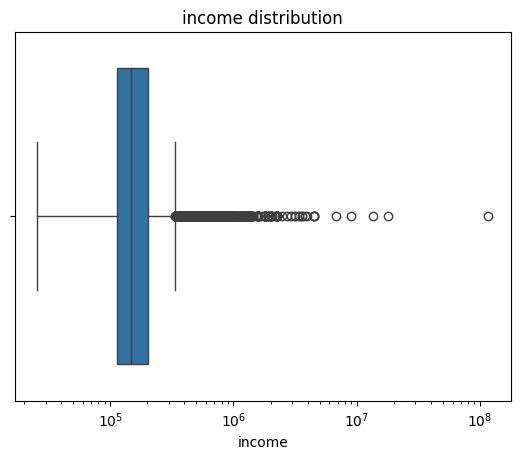

In [35]:
sns.boxplot(x=work["AMT_INCOME_TOTAL"])
plt.xscale("log")
plt.title("income distribution")
plt.xlabel("income")
plt.show()

Income by contract type.

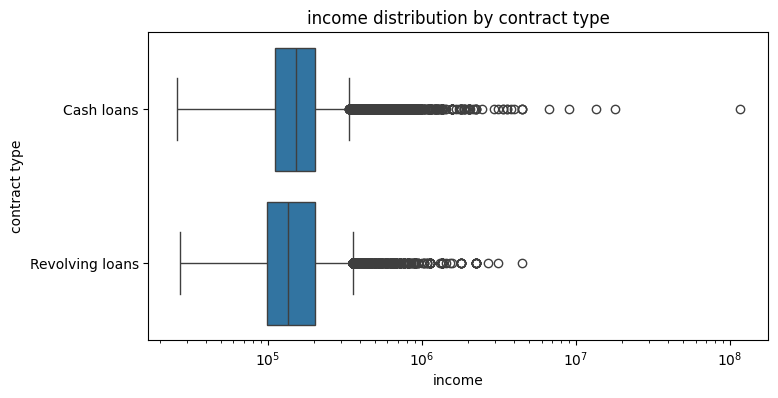

In [36]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=work["AMT_INCOME_TOTAL"], y=work["NAME_CONTRACT_TYPE"])
plt.xscale("log")
plt.title("income distribution by contract type")
plt.xlabel("income")
plt.ylabel("contract type")
plt.show()

Count outliers with the IQR rule: values below Q1 - 1.5*IQR or above Q3 + 1.5*IQR.

In [37]:
Q1 = work["AMT_INCOME_TOTAL"].quantile(0.25)
Q3 = work["AMT_INCOME_TOTAL"].quantile(0.75)
IQR = Q3 - Q1
low = Q1 - 1.5 * IQR
high = Q3 + 1.5 * IQR
outliers = work[(work["AMT_INCOME_TOTAL"] < low) | (work["AMT_INCOME_TOTAL"] > high)]
print("lower limit:", low, "upper limit:", high)
print("outliers:", len(outliers))
print("maximum income:", work["AMT_INCOME_TOTAL"].max())

lower limit: -22500.0 upper limit: 337500.0
outliers: 14035
maximum income: 117000000.0


Boxplots of credit amount, annuity and age.

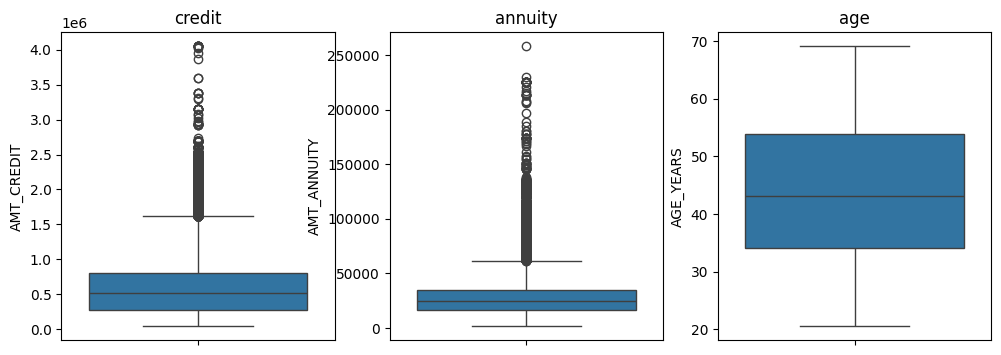

In [38]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
sns.boxplot(y=work["AMT_CREDIT"])
plt.title("credit")
plt.subplot(1, 3, 2)
sns.boxplot(y=work["AMT_ANNUITY"])
plt.title("annuity")
plt.subplot(1, 3, 3)
sns.boxplot(y=work["AGE_YEARS"])
plt.title("age")
plt.show()

**Observation**:AMT_INCOME_TOTAL has [x] outliers with a maximum of [x]. Income, credit and annuity are right-skewed. These look like real high earners, so the rows are kept; a log transform or tree-based models can handle them later.

Split the columns into numerical and categorical.

In [39]:
numerical_cols = work.select_dtypes(include="number").columns.drop(["SK_ID_CURR", "TARGET"])
categorical_cols = work.select_dtypes(include="object").columns
print(len(numerical_cols), "numerical columns")
print(len(categorical_cols), "categorical columns")

107 numerical columns
16 categorical columns


Compare the distribution of the external scores for non-defaulters (0) and defaulters (1).

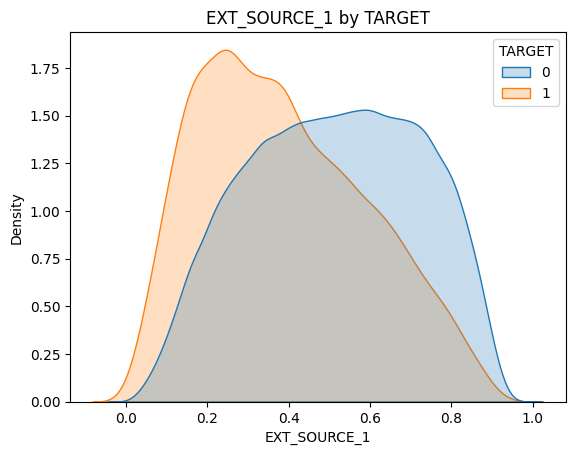

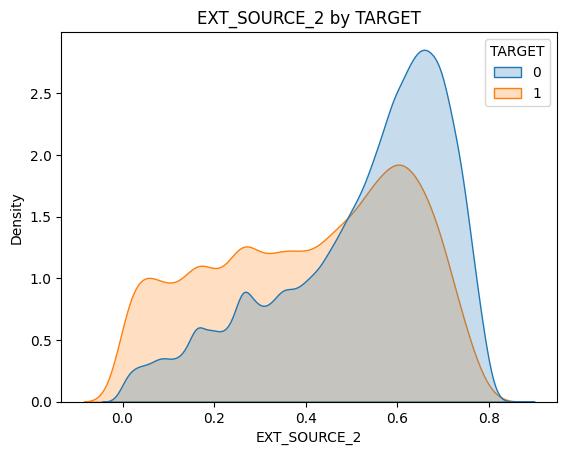

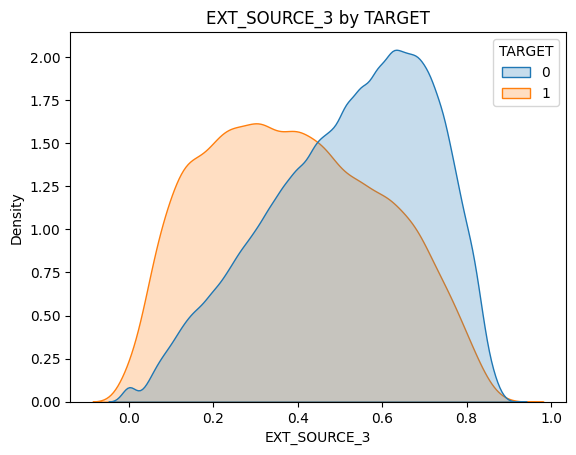

In [40]:
for col in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]:
    sns.kdeplot(data=work, x=col, hue="TARGET", common_norm=False, fill=True)
    plt.title(col + " by TARGET")
    plt.show()

Compare age and employment length by target.

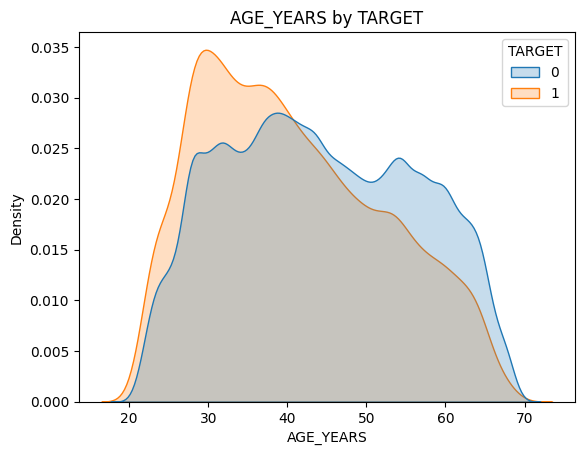

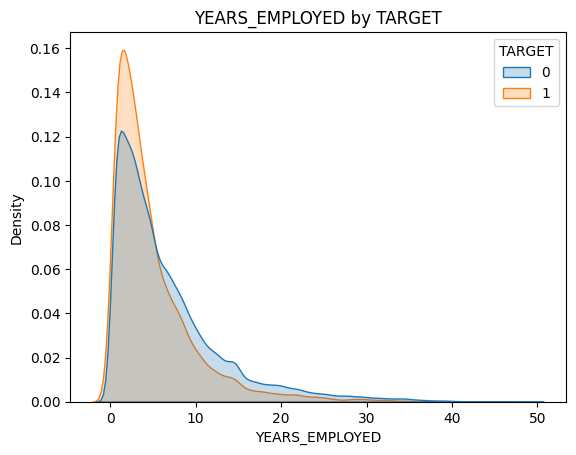

In [41]:
for col in ["AGE_YEARS", "YEARS_EMPLOYED"]:
    sns.kdeplot(data=work, x=col, hue="TARGET", common_norm=False, fill=True)
    plt.title(col + " by TARGET")
    plt.show()

Default rate by age group.

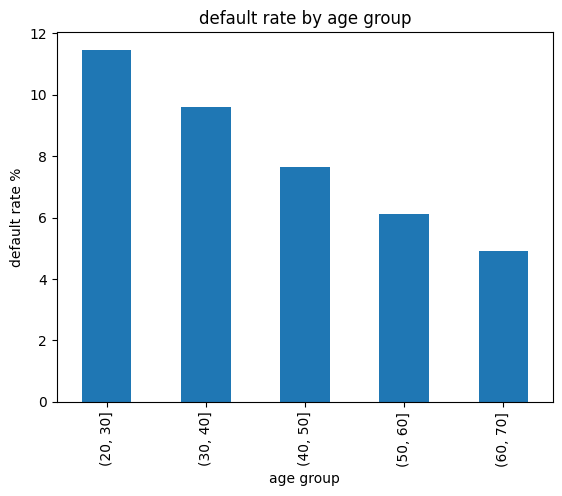

In [42]:
work["AGE_GROUP"] = pd.cut(work["AGE_YEARS"], [20, 30, 40, 50, 60, 70])
age_rate = work.groupby("AGE_GROUP", observed=True)["TARGET"].mean() * 100
age_rate.plot.bar()
plt.title("default rate by age group")
plt.xlabel("age group")
plt.ylabel("default rate %")
plt.show()

**Observation**:Defaulters have lower EXT_SOURCE scores, so these are strong predictors. Younger clients and clients with shorter employment default more.

Correlation of each numeric column with TARGET.

In [43]:
corr = work.corr(numeric_only=True)["TARGET"].drop("TARGET").sort_values()
display(corr.head(10))
display(corr.tail(10))

,TARGET
EXT_SOURCE_3,-0.178919
EXT_SOURCE_2,-0.160472
EXT_SOURCE_1,-0.155317
AGE_YEARS,-0.078239
YEARS_EMPLOYED,-0.074958
FLOORSMAX_AVG,-0.044003
FLOORSMAX_MEDI,-0.043768
FLOORSMAX_MODE,-0.043226
AMT_GOODS_PRICE,-0.039645
REGION_POPULATION_RELATIVE,-0.037227


,TARGET
FLAG_DOCUMENT_3,0.044346
REG_CITY_NOT_LIVE_CITY,0.044395
FLAG_EMP_PHONE,0.045982
REG_CITY_NOT_WORK_CITY,0.050994
DAYS_ID_PUBLISH,0.051457
DAYS_LAST_PHONE_CHANGE,0.055218
REGION_RATING_CLIENT,0.058899
REGION_RATING_CLIENT_W_CITY,0.060893
DAYS_EMPLOYED,0.074958
DAYS_BIRTH,0.078239


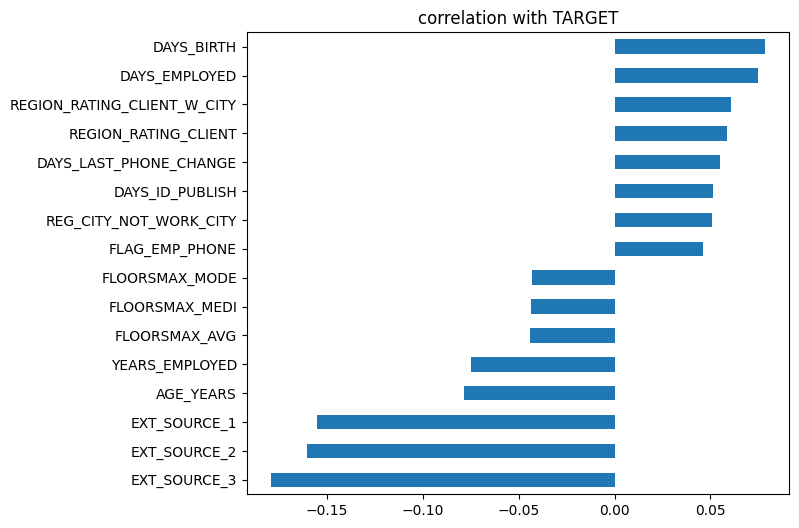

In [44]:
top = pd.concat([corr.head(8), corr.tail(8)])
top.plot.barh(figsize=(7, 6))
plt.title("correlation with TARGET")
plt.show()

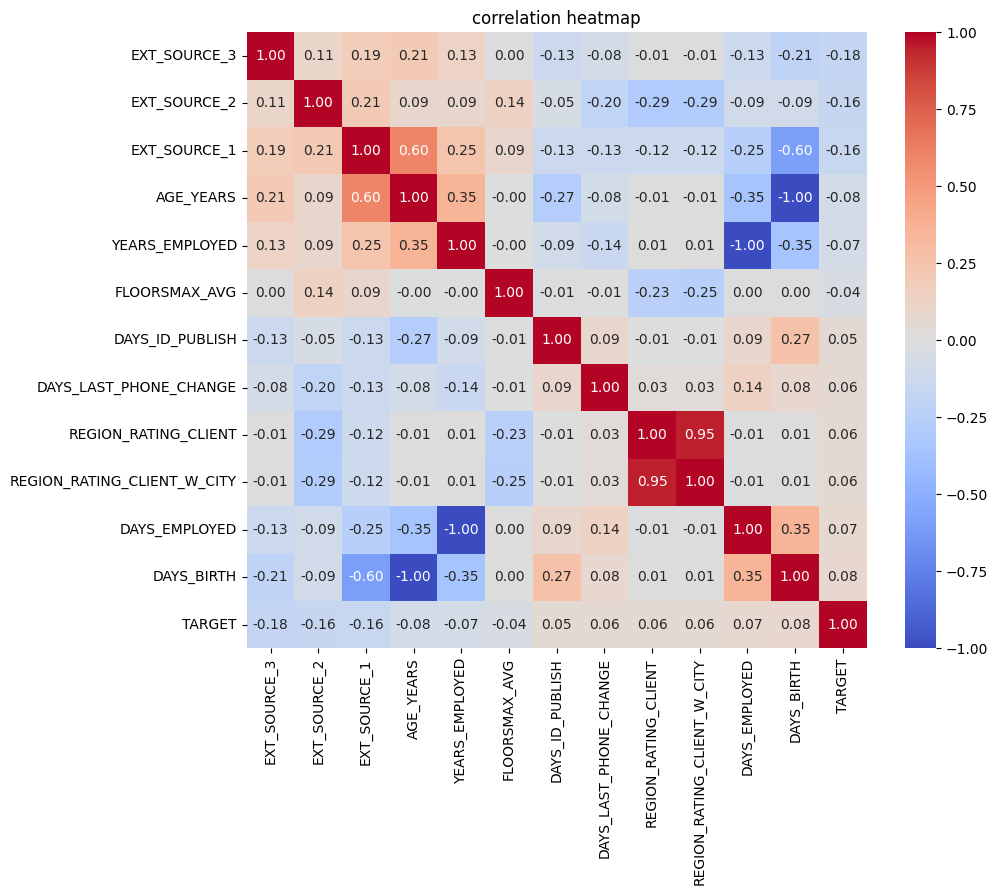

In [45]:
selected = list(corr.head(6).index) + list(corr.tail(6).index) + ["TARGET"]
plt.figure(figsize=(10, 8))
sns.heatmap(work[selected].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("correlation heatmap")
plt.show()

**Observation**:The most negative correlations are [EXT_SOURCE_3, EXT_SOURCE_2, EXT_SOURCE_1] and the most positive is [DAYS_BIRTH]. All correlations are weak (below about [0.2]), so no single feature predicts default alone.

Number of categories and missing values in each categorical column.

In [46]:
cat_info = pd.DataFrame({
    "n_categories": work[categorical_cols].nunique(),
    "missing_%": (work[categorical_cols].isna().mean() * 100).round(2)
})
display(cat_info.sort_values("n_categories", ascending=False))

,n_categories,missing_%
ORGANIZATION_TYPE,58,0.00
OCCUPATION_TYPE,18,31.35
NAME_INCOME_TYPE,8,0.00
NAME_TYPE_SUITE,7,0.42
WALLSMATERIAL_MODE,7,50.84
WEEKDAY_APPR_PROCESS_START,7,0.00
NAME_FAMILY_STATUS,6,0.00
NAME_HOUSING_TYPE,6,0.00
NAME_EDUCATION_TYPE,5,0.00
FONDKAPREMONT_MODE,4,68.39


Default rate by education level.

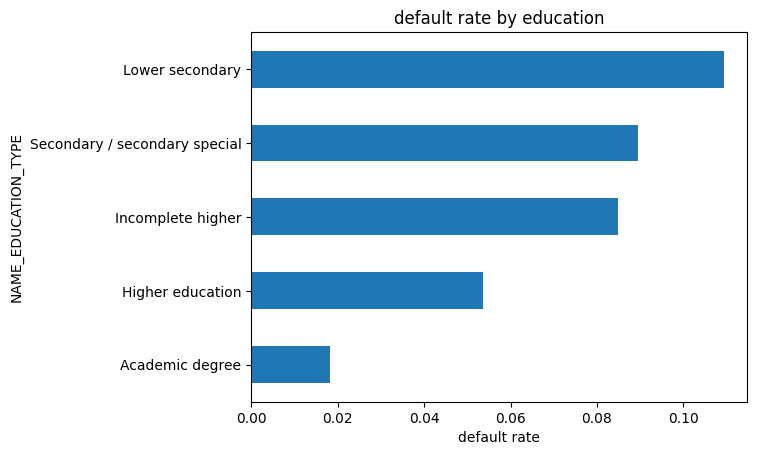

In [47]:
work.groupby("NAME_EDUCATION_TYPE")["TARGET"].mean().sort_values().plot.barh()
plt.title("default rate by education")
plt.xlabel("default rate")
plt.show()

Default rate by income type

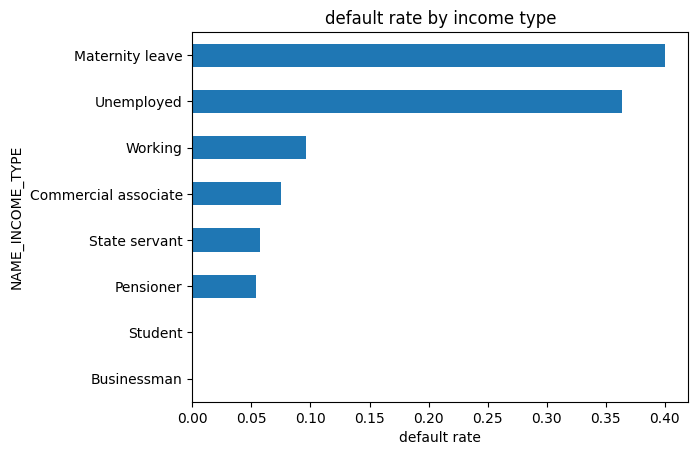

In [48]:
work.groupby("NAME_INCOME_TYPE")["TARGET"].mean().sort_values().plot.barh()
plt.title("default rate by income type")
plt.xlabel("default rate")
plt.show()

Default rate by occupation.

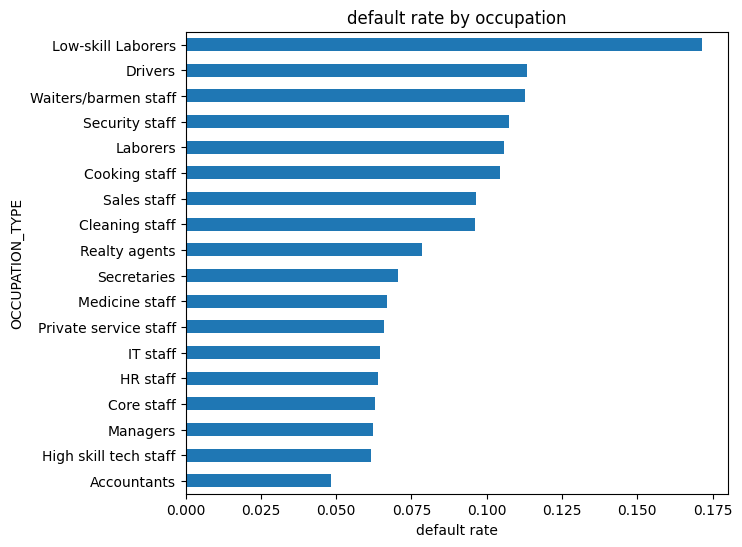

In [49]:
work.groupby("OCCUPATION_TYPE")["TARGET"].mean().sort_values().plot.barh(figsize=(7, 6))
plt.title("default rate by occupation")
plt.xlabel("default rate")
plt.show()

Default rate by contract type and gender.

In [50]:
work.groupby("NAME_CONTRACT_TYPE")["TARGET"].mean()

,TARGET
NAME_CONTRACT_TYPE,
Cash loans,0.083459
Revolving loans,0.054783


In [51]:
work.groupby("CODE_GENDER")["TARGET"].mean()

,TARGET
CODE_GENDER,
F,0.069993
M,0.101419
XNA,0.000000


Observation:Lower education levels and [laborer] jobs have higher default rates, while [pensioners / state servants / higher education] have lower rates. Cash loans default more than revolving loans. OCCUPATION_TYPE has many categories and missing values, so it needs careful encoding.

Historical dataset
Each history table has many rows per client. We check how many clients each table covers and how many rows each client has on average.

In [52]:
print("bureau clients:", bureau["SK_ID_CURR"].nunique())
print(bureau.groupby("SK_ID_CURR").size().describe())

bureau clients: 305811
count    305811.000000
mean          5.612709
std           4.430354
min           1.000000
25%           2.000000
50%           4.000000
75%           8.000000
max         116.000000
dtype: float64


In [53]:
print("previous application clients:", prev["SK_ID_CURR"].nunique())
print(prev.groupby("SK_ID_CURR").size().describe())

previous application clients: 338857
count    338857.000000
mean          4.928964
std           4.220716
min           1.000000
25%           2.000000
50%           4.000000
75%           7.000000
max          77.000000
dtype: float64


In [54]:
print("installments clients:", inst["SK_ID_CURR"].nunique())
print("credit card clients:", cc["SK_ID_CURR"].nunique())

installments clients: 339587
credit card clients: 103558


Share of training clients that have history in each table.

In [55]:
print("bureau:", work["SK_ID_CURR"].isin(bureau["SK_ID_CURR"]).mean() * 100)
print("previous_application:", work["SK_ID_CURR"].isin(prev["SK_ID_CURR"]).mean() * 100)
print("installments:", work["SK_ID_CURR"].isin(inst["SK_ID_CURR"]).mean() * 100)
print("credit card:", work["SK_ID_CURR"].isin(cc["SK_ID_CURR"]).mean() * 100)

bureau: 85.68506492450678
previous_application: 94.64929709831517
installments: 94.83985938714387
credit card: 28.260777663238063


Bureau: status and type of the credits.

In [56]:
display(bureau["CREDIT_ACTIVE"].value_counts(normalize=True) * 100)
display(bureau["CREDIT_TYPE"].value_counts().head(8))

,proportion
CREDIT_ACTIVE,
Closed,62.879014
Active,36.739496
Sold,0.380266
Bad debt,0.001223


,count
CREDIT_TYPE,
Consumer credit,1251615
Credit card,402195
Car loan,27690
Mortgage,18391
Microloan,12413
Loan for business development,1975
Another type of loan,1017
Unknown type of loan,555


Previous applications: how many were approved or refused.

In [57]:
display(prev["NAME_CONTRACT_STATUS"].value_counts(normalize=True) * 100)

,proportion
NAME_CONTRACT_STATUS,
Approved,62.074740
Canceled,18.938831
Refused,17.403638
Unused offer,1.582791


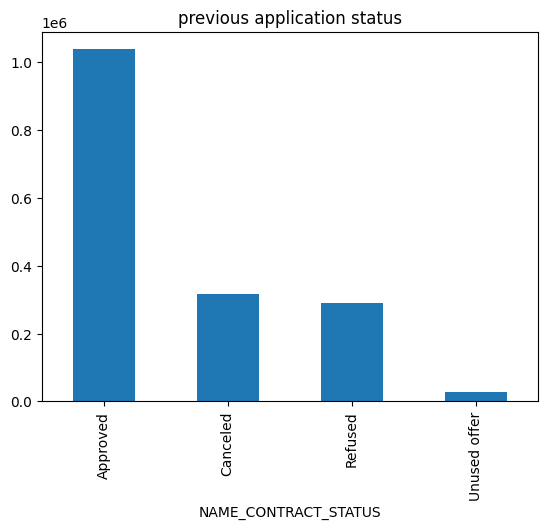

In [58]:
prev["NAME_CONTRACT_STATUS"].value_counts().plot.bar()
plt.title("previous application status")
plt.show()

Instalments: how often clients pay late. DAYS_LATE is the payment date minus the due date, so a positive value means late.

In [59]:
inst["DAYS_LATE"] = inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"]
print("payments made late (%):", (inst["DAYS_LATE"] > 0).mean() * 100)

payments made late (%): 8.428042657471103


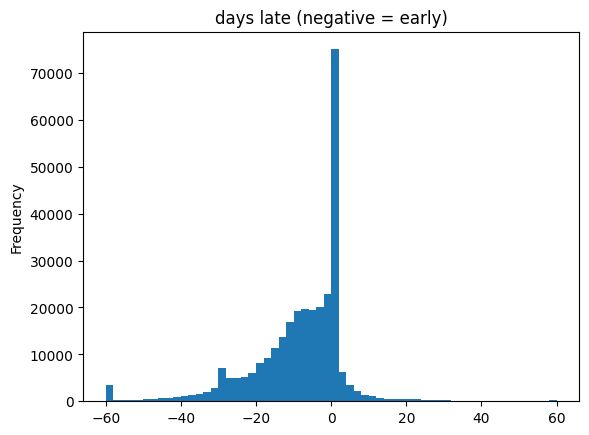

In [60]:
inst["DAYS_LATE"].clip(-60, 60).dropna().sample(300000, random_state=1).plot.hist(bins=60)
plt.title("days late (negative = early)")
plt.show()

Do the history tables help predict default? For each client we calculate the share of late payments, then compare default rates across groups. Clients without history form their own group.

In [61]:
late_share = (inst["DAYS_LATE"] > 0).groupby(inst["SK_ID_CURR"]).mean().rename("LATE_SHARE")
tmp = work[["SK_ID_CURR", "TARGET"]].merge(late_share, on="SK_ID_CURR", how="left")
tmp["group"] = pd.cut(tmp["LATE_SHARE"], [-0.01, 0, 0.1, 0.3, 1], labels=["never late", "up to 10%", "up to 30%", "over 30%"]).astype(object).fillna("no history")
late_result = tmp.groupby("group")["TARGET"].agg(["mean", "size"])
display(late_result)

,mean,size
group,,
never late,0.068009,136644
no history,0.059806,15868
over 30%,0.133541,17650
up to 10%,0.079635,77139
up to 30%,0.101030,60210


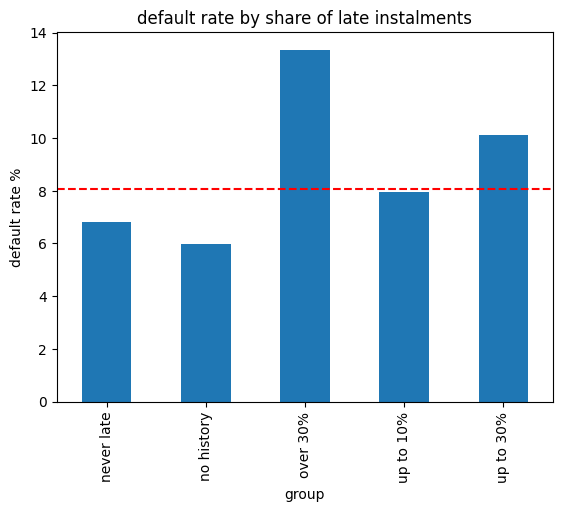

In [62]:
(late_result["mean"] * 100).plot.bar()
plt.axhline(work["TARGET"].mean() * 100, color="red", linestyle="--")
plt.title("default rate by share of late instalments")
plt.ylabel("default rate %")
plt.show()

Same test with the share of refused previous applications.

In [63]:
refused = (prev["NAME_CONTRACT_STATUS"] == "Refused").groupby(prev["SK_ID_CURR"]).mean().rename("REFUSED_SHARE")
tmp2 = work[["SK_ID_CURR", "TARGET"]].merge(refused, on="SK_ID_CURR", how="left")
tmp2["group"] = pd.cut(tmp2["REFUSED_SHARE"], [-0.01, 0, 0.25, 0.5, 1], labels=["none", "up to 25%", "up to 50%", "over 50%"]).astype(object).fillna("no history")
refused_result = tmp2.groupby("group")["TARGET"].agg(["mean", "size"])
display(refused_result)

,mean,size
group,,
no history,0.059560,16454
none,0.070732,190763
over 50%,0.159258,11158
up to 25%,0.081144,47397
up to 50%,0.113299,41739


Clients have many rows in the history tables, so these must be aggregated to one row per client before modelling. Coverage differs by table; credit card is the sparsest ([x]% of clients). Clients with a higher share of late payments or refused applications default more, so aggregate features from these tables look useful. Clients without history need a separate "no history" treatment.

Data-quality report. For every table we record the size, the overall percentage of missing values and the number of duplicate rows.

In [64]:
names = ["application_train", "application_test", "bureau", "bureau_balance",
         "previous_application", "POS_CASH_balance", "installments_payments", "credit_card_balance"]
dfs = [work, test, bureau, bureau_bal, prev, pos, inst, cc]

report = pd.DataFrame({
    "table": names,
    "rows": [d.shape[0] for d in dfs],
    "columns": [d.shape[1] for d in dfs],
    "missing_%": [round(d.isna().sum().sum() / d.size * 100, 2) for d in dfs],
    "duplicate_rows": [d.duplicated().sum() for d in dfs]
})
display(report)

,table,rows,columns,missing_%,duplicate_rows
0,application_train,307511,126,23.91,0
1,application_test,48744,121,23.81,0
2,bureau,1716428,17,13.50,0
3,bureau_balance,27299925,3,0.00,0
4,previous_application,1670214,37,17.98,0
5,POS_CASH_balance,10001358,8,0.07,0
6,installments_payments,13605401,9,0.01,0
7,credit_card_balance,3840312,23,6.65,0


In [65]:
report.to_csv("data_quality_report.csv", index=False)

Key data-quality findings
1. Missing values in the housing features and OWN_CAR_AGE.
2. Placeholder value 365243 in DAYS_EMPLOYED.
3. "XNA" (unknown) values in CODE_GENDER and ORGANIZATION_TYPE.
4. Strong outliers in income, credit and annuity.
5. Strong class imbalance in TARGET.
6. History tables have many rows per client and need aggregation.

Conclusion
Conclusion
- About [8]% of clients are defaulters, so the target is imbalanced.
- Cleaning needed: replace 365243, handle missing values and XNA.
- EXT_SOURCE scores, age, education and income type are important features.
- History tables must be aggregated to one row per client.
- Next step: feature engineering and model building.

In [66]:
!mkdir -p /content/drive/MyDrive/home_credit/outputs
!cp dataset_description.csv data_quality_report.csv /content/drive/MyDrive/home_credit/outputs/